# ICS5111 · Session 02: walkthrough notebook
## Explore: graph embeddings

This notebook follows the six parts of the Session 02 slides. Each section reproduces one result from the slides, with the same helper code, settings and seed, so that every number you saw can be checked and changed. Sections W1 to W10 are cited on the slides.

| Part of the slides | Walkthrough sections |
|---|---|
| 1 From graph analysis to graph machine learning | W1, W2 |
| 2 Learning from context: skip-gram | W3 |
| 3 DeepWalk: random walks as sentences | W2, W4 |
| 4 node2vec: biased random walks | W5, W6 |
| 5 Using embeddings: classification and link prediction | W7, W8 |
| 6 Beyond the lookup table | W9, W10 (optional) |

**How to use it.** Where a cell says *predict before running*, write your prediction first. Each code cell has a short lead-in, and the cells that compute something are followed by a reading of the output. The longer runs take a few seconds each on a CPU; no GPU is needed. In class we run selected sections in groups of three; the group checkpoints say what to record.

### Setup

The next two cells install the course library, `ai-learning-kit`, and start Session 02: the helper functions (`T`), the reference results and Cora, which the library downloads from its publisher, LINQS, the first time it is needed. In Notebook Tutor the first cell is skipped, because the tutor already includes the library; in Colab the install takes about a minute (choose *Run anyway* if Colab warns that the notebook was not written by Google). Nothing has to be downloaded or uploaded by hand.

In [ ]:
%pip install -q "ai-learning-kit[graphs]@https://github.com/charlieabela/ai-learning-kit/archive/refs/tags/v0.5.0.zip"

In [2]:
import ai_learning_kit as kit
kit.start("ICS5111", "S02")       # also downloads Cora from LINQS the first time
T = kit.tools()                   # the Session 02 helper functions

import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from IPython.display import display
import json, platform
SEED = T.SEED
print("helpers", T.VERSION, "| Python", platform.python_version(), "| numpy", np.__version__, "| networkx", nx.__version__)

ai-learning-kit 0.5.0 · ICS5111 S02: Graph embeddings
Data: Cora citation network (LINQS), from LINQS Statistical Relational Learning Group, UC Santa Cruz (checked)
Helpers: T = kit.tools(). This session has no answer book: the notebook checks itself.
helpers 2026-10-27 | Python 3.12.3 | numpy 2.5.4 | networkx 3.7


## W1 · Session 01 measures as handcrafted node features
*Slides, Part 1.* The most direct way to give a node a vector is to compute measures we already know. Here are degree, clustering and PageRank for the seven-node graph of Session 01. **Predict before running:** which nodes will receive identical rows?

,degree,clustering,PageRank
node,,,
1,2,1.00,0.127
2,3,0.33,0.183
3,2,1.00,0.127
4,2,0.00,0.125
5,3,0.33,0.183
6,2,1.00,0.127
7,2,1.00,0.127


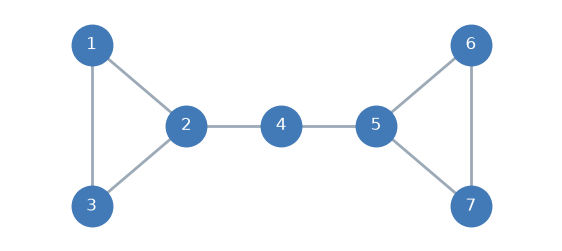

In [3]:
toy = T.toy_graph()
features = pd.DataFrame({"degree": dict(toy.degree()),
                         "clustering": nx.clustering(toy),
                         "PageRank": nx.pagerank(toy)}).sort_index()
features.index.name = "node"
display(features.round({"clustering": 2, "PageRank": 3}))
T.draw_toy(); plt.show()

**Reading the output.** Nodes 1, 3, 6 and 7 receive identical rows (degree 2, clustering 1, PageRank 0.127), and so do nodes 2 and 5. The features describe *how* a node is connected, not *where* it sits or *who* its neighbours are: nothing in the table says that 1 and 3 belong with 2 rather than with 6 and 7. Section W7 measures what this costs on Cora, where these three features predict a paper's topic barely better than always guessing the largest topic.

## W2 · From a walk to training pairs, and a first embedding
*Slides, Parts 1 and 3.* A random walk is read as a sentence and cut into (centre, context) pairs by a window that counts **positions** in the walk, not graph distance. **Predict before running:** how many pairs does the walk 1, 2, 4, 5, 6 give with a window of 2, and which pairs have centre 4?

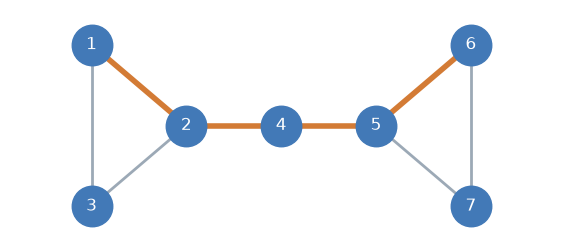

pairs with window 2: 14 | with window 1: 8
pairs with centre 4: [(4, 1), (4, 2), (4, 5), (4, 6)]


In [4]:
example = [1, 2, 4, 5, 6]
T.draw_toy(highlight=example); plt.show()
pairs = T.context_pairs([example], window=2)
print("pairs with window 2:", len(pairs), "| with window 1:", len(T.context_pairs([example], window=1)))
print("pairs with centre 4:", [tuple(map(int, p)) for p in pairs if p[0] == 4])

**Reading the output.** Five positions give 14 ordered pairs with window 2 (the end positions have fewer neighbours in the sequence) and 8 with window 1. Centre 4 is paired with 1, 2, 5 and 6: node 1 is two hops away in the graph but within two positions in the walk, which is what counts.

Next, the whole pipeline on the same graph. We start 50 walks of length 10 from every node, cut them into pairs with window 2, and learn **two-dimensional** vectors with skip-gram and negative sampling, so that we can draw them. `sgns_snapshots` is the same training routine as the helper used for Cora, but it keeps a copy of the vectors after every epoch.

walks: 350 | training pairs: 11900


,coordinate 1,coordinate 2
node,,
1,-1.501,-1.921
2,-0.586,-1.105
3,-1.429,-1.946
4,0.360,-0.561
5,1.016,-0.758
6,2.012,-1.296
7,1.950,-1.395


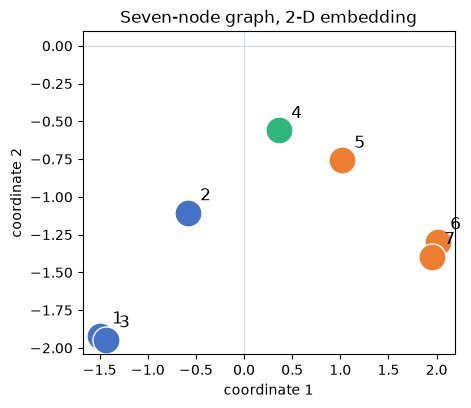

In [5]:
walks7 = T.walks(toy, n_walks=50, length=10, seed=SEED)
pairs7 = T.context_pairs(walks7, window=2)
print("walks:", len(walks7), "| training pairs:", len(pairs7))
snaps7, losses7 = T.sgns_snapshots(pairs7 - 1, 7, dim=2, negatives=3, epochs=40, lr=.02)   # nodes 1..7 -> rows 0..6
Z7 = snaps7[-1]
display(pd.DataFrame(Z7.round(3), index=range(1, 8), columns=["coordinate 1", "coordinate 2"]).rename_axis("node"))
fig, ax = plt.subplots(figsize=(4.8, 4.2))
colours = {1: "#4472C4", 2: "#4472C4", 3: "#4472C4", 4: "#2FB67C", 5: "#ED7D31", 6: "#ED7D31", 7: "#ED7D31"}
for n in range(1, 8):
    ax.scatter(*Z7[n - 1], s=380, color=colours[n], edgecolor="white", zorder=2)
    ax.annotate(str(n), Z7[n - 1], xytext=(9, 9), textcoords="offset points", fontsize=12)
ax.axhline(0, color="#D0D5DD", lw=.8); ax.axvline(0, color="#D0D5DD", lw=.8)
ax.set(xlabel="coordinate 1", ylabel="coordinate 2", title="Seven-node graph, 2-D embedding"); plt.show()

**Reading the output.** Of the 11,900 pairs, those between nodes of the same triangle are the most frequent, so each triangle gathers in one region and node 4 lies between them. Nodes 1 and 3 receive almost the same vector, as do 6 and 7: their neighbourhoods are identical, so the walks treat them identically. The slides (Part 1) show this figure. Note what has changed since W1: the vector now says *where* a node sits, which the handcrafted features could not.

## W3 · Skip-gram arithmetic: the softmax and one negative-sampling update
*Slides, Part 2.* Skip-gram scores a (centre, context) pair by the dot product of a centre vector $z_u$ and a context vector $c_v$. The full softmax turns the scores of all candidate contexts into probabilities:
$$P(v\mid u)=\frac{\exp(z_u^\top c_v)}{\sum_{k}\exp(z_u^\top c_k)}, \qquad \ell(u,v) = -\log P(v \mid u).$$
**Predict before running:** with three candidates scoring 1, 0 and −1, what is the probability of the first?

In [6]:
scores = np.array([1., 0., -1.])
weights = np.exp(scores - scores.max())          # subtracting the maximum keeps exp() stable
probabilities = weights / weights.sum()
display(pd.DataFrame({"score": scores, "exp(score)": np.exp(scores).round(3), "probability": probabilities.round(3)},
                     index=["first (observed)", "second", "third"]))
print("loss when the first context is observed:", round(-np.log(probabilities[0]), 2))

,score,exp(score),probability
first (observed),1.0,2.718,0.665
second,0.0,1.000,0.245
third,-1.0,0.368,0.090


loss when the first context is observed: 0.41


**Reading the output.** The probabilities are 0.665, 0.245 and 0.090, and the loss is $-\log(0.665) = 0.41$. The denominator sums over every candidate, which is 2,708 terms per pair for Cora. Negative sampling replaces it with $K$ yes-or-no questions: is this a real context or a random one?
$$\ell(u,v)=-\log\sigma(z_u^\top c_v)-\sum_{i=1}^{K}\log\sigma(-z_u^\top c_{n_i}), \qquad \sigma(s) = \frac{1}{1+e^{-s}}.$$
The next cell makes one update for centre node 4, observed context 5 and noise contexts 1 and 7, with a learning rate of 0.5. Both updates use the **old** vectors. **Predict before running:** which scores go up and which go down?

In [7]:
from scipy.special import expit as sigma
z4 = np.array([.8, .4])
contexts = {"5 (observed)": np.array([.3, .6]), "1 (noise)": np.array([.6, .1]), "7 (noise)": np.array([.2, .5])}
label = {"5 (observed)": 1, "1 (noise)": 0, "7 (noise)": 0}
eta = 0.5
before = {k: sigma(z4 @ c) for k, c in contexts.items()}
error = {k: sigma(z4 @ c) - label[k] for k, c in contexts.items()}          # derivative of the loss w.r.t. each score
z4_new = z4 - eta * sum(error[k] * c for k, c in contexts.items())         # centre vector: one step
contexts_new = {k: c - eta * error[k] * z4 for k, c in contexts.items()}    # each context vector: one step
after = {k: sigma(z4_new @ contexts_new[k]) for k in contexts}
display(pd.DataFrame({"before": before, "after one update": after}).round(3))
loss = lambda z, cs: -np.log(sigma(z @ cs["5 (observed)"])) - sum(np.log(sigma(-z @ cs[k])) for k in ["1 (noise)", "7 (noise)"])
print("loss before:", round(loss(z4, contexts), 3), "| after:", round(loss(z4_new, contexts_new), 3))

,before,after one update
5 (observed),0.618,0.623
1 (noise),0.627,0.551
7 (noise),0.589,0.527


loss before: 2.358 | after: 2.021


**Reading the output.** The observed score rises slightly (0.618 to 0.623) and both noise scores fall (0.627 to 0.551 and 0.589 to 0.527), so the loss falls. One update is a small move; training repeats it hundreds of thousands of times. A noise context is a random contrast drawn in proportion to frequency$^{0.75}$, not a statement that nodes 4 and 1 are unrelated. Also note that a lower loss is not yet evidence that the vectors help any task: that needs the held-out evaluation of W7.

## W4 · DeepWalk on the karate club
*Slides, Part 3.* Zachary's karate club split into two factions, around the instructor (member 0) and the administrator (member 33). DeepWalk sees only the 78 friendships. We start 10 walks of length 20 from each of the 34 members, use window 3, and learn two-dimensional vectors so that we can watch them train. The faction labels are used **only** to colour the plots and to score the result afterwards.

members: 34 | friendships: 78 | walks: 340 | pairs: 36720
loss per positive pair, epoch 1: 3.656 | epoch 30: 2.352


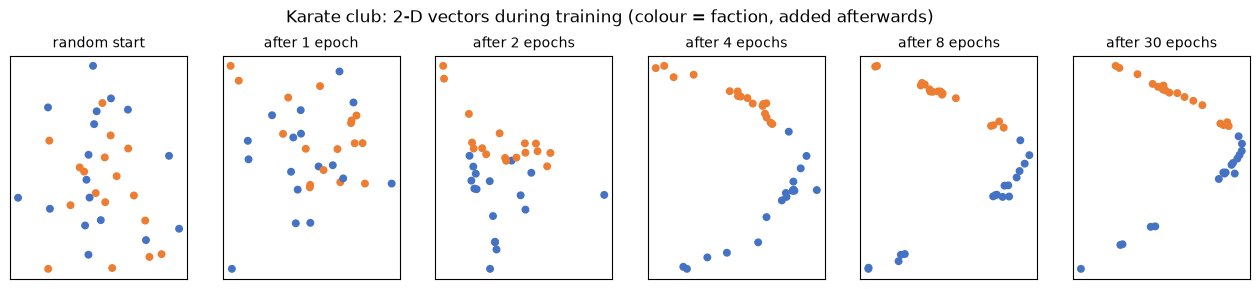

In [8]:
kg, club = T.karate()
kwalks = T.walks(kg, n_walks=10, length=20, seed=SEED)
kpairs = T.context_pairs(kwalks, window=3)
ksnaps, klosses = T.sgns_snapshots(kpairs, kg.number_of_nodes(), dim=2, negatives=5, epochs=30, lr=.002)
print("members:", kg.number_of_nodes(), "| friendships:", kg.number_of_edges(), "| walks:", len(kwalks), "| pairs:", len(kpairs))
print("loss per positive pair, epoch 1:", round(klosses[0], 3), "| epoch 30:", round(klosses[-1], 3))
cols = np.where(club == 1, "#ED7D31", "#4472C4")
fig, axs = plt.subplots(1, 6, figsize=(16, 2.9))
for ax, e in zip(axs, [0, 1, 2, 4, 8, 30]):
    Ze = ksnaps[e] - ksnaps[e].mean(0)
    ax.scatter(Ze[:, 0], Ze[:, 1], c=cols, s=22)
    ax.set_title("random start" if e == 0 else f"after {e} epoch{'s' if e > 1 else ''}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Karate club: 2-D vectors during training (colour = faction, added afterwards)", y=1.04); plt.show()

**Reading the output.** From a random start the members separate into two groups within a few epochs, and the groups match the factions. To test this without using the factions in training, we label **only the two leaders** and assign every other member to the leader whose vector points in the more similar direction (cosine similarity). **Predict before running:** how many of the other 32 members will be assigned correctly?

In [9]:
Zk = ksnaps[-1]
Zn = Zk / np.linalg.norm(Zk, axis=1, keepdims=True)
pred = (Zn @ Zn[33] > Zn @ Zn[0]).astype(int)          # 1 = closer to the administrator's vector
others = np.arange(1, 33)
correct = int((pred[others] == club[others]).sum())
print(f"correct: {correct} of {len(others)}; wrong: {[int(i) for i in others if pred[i] != club[i]]}")

correct: 31 of 32; wrong: [8]


**Reading the output.** 31 of 32 members are assigned correctly from two labels. The one error is member 8, number 9 in Zachary's own numbering, the same member that Zachary's 1977 flow model misassigned: he went with the instructor although his ties pointed the other way. DeepWalk recovered the community structure from the friendships alone, which is what it is designed to do.

## W5 · node2vec: biased walks
*Slides, Part 4.* node2vec makes each step depend on the previous node $t$ as well as the current node $v$. A candidate $x$ gets weight $1/p$ if it returns to $t$, $1$ if it is also a neighbour of $t$, and $1/q$ if it moves two steps away from $t$:
$$P(x\mid t,v)=\frac{\alpha_{pq}(t,x)\,w_{vx}}{\sum_{y\in N(v)}\alpha_{pq}(t,y)\,w_{vy}}.$$
On the seven-node graph, the walk has just moved from 1 to 2; the candidates are 1 (return), 3 (near 1) and 4 (away). **Predict before running:** the three probabilities for $p = 2$, $q = 0.5$.

In [10]:
rows = []
for p, q in [(1, 1), (2, .5), (2, 2), (1, .25)]:
    ns, pr = T.transition(toy, 1, 2, p=p, q=q)
    rows.append({"setting": f"p={p:g}, q={q:g}", **{f"to {n}": round(float(v), 3) for n, v in zip(ns, pr)}})
display(pd.DataFrame(rows).set_index("setting"))

,to 1,to 3,to 4
setting,,,
"p=1, q=1",0.333,0.333,0.333
"p=2, q=0.5",0.143,0.286,0.571
"p=2, q=2",0.250,0.500,0.250
"p=1, q=0.25",0.167,0.167,0.667


**Reading the output.** For $p = 2$, $q = 0.5$ the unnormalised weights are 0.5, 1 and 2, which sum to 3.5, giving 1/7, 2/7 and 4/7: the walk is four times as likely to move outward to 4 as to return to 1. With $p = q = 1$ every weight is 1, which is DeepWalk's uniform walk.

### Group exercise: complete the transition yourself
Complete `bias` and `probabilities` below. Distances are measured from the **previous** node. Expected output for previous 1, current 2, $p = 2$, $q = 0.5$: candidates [1, 3, 4] and probabilities [1/7, 2/7, 4/7]. The cell stops with a message, not an error, until both expressions are filled in.

In [11]:
def my_transition(previous, current, p, q):
    G = T.toy_graph()
    candidates = sorted(G.neighbors(current))
    weights = []
    for x in candidates:
        # TODO: 1/p if x is the previous node; 1 if x is a neighbour of the previous node; 1/q otherwise.
        bias = None
        if bias is None:
            return None
        weights.append(bias)
    weights = np.asarray(weights, dtype=float)
    probabilities = None   # TODO: normalise the weights so that they sum to 1.
    return candidates, probabilities

answer = my_transition(previous=1, current=2, p=2, q=.5)
if answer is None or answer[1] is None:
    print("Complete the two TODO expressions, then rerun. The table above gives the expected values.")
else:
    candidates, pr = answer
    assert candidates == [1, 3, 4]
    assert np.allclose(pr, [1/7, 2/7, 4/7]), "Check the distance from the previous node, then normalise."
    print("Transition check passed:", np.round(pr, 3))

Complete the two TODO expressions, then rerun. The table above gives the expected values.

### Probabilities and finite samples
The next cell draws the next step from the same state (previous 1, current 2) 30 times and 3,000 times. **Predict before running:** will the 30 draws match 1/7, 2/7 and 4/7?

In [12]:
candidates, pr = T.transition(toy, 1, 2, p=2, q=.5)
rng = np.random.default_rng(SEED)
rows = []
for draws in [30, 3000]:
    sample = rng.choice(candidates, size=draws, p=pr)
    rows.append({"draws": draws, **{f"to {x}": round(float(np.mean(sample == x)), 3) for x in candidates}})
rows.append({"draws": "theory", **{f"to {x}": round(float(v), 3) for x, v in zip(candidates, pr)}})
display(pd.DataFrame(rows).set_index("draws"))

,to 1,to 3,to 4
draws,,,
30,0.167,0.267,0.567
3000,0.148,0.299,0.553
theory,0.143,0.286,0.571


**Reading the output.** Thirty draws can be far from the probabilities; three thousand are close. Training uses hundreds of thousands of steps, so the bias set by $p$ and $q$ shows up reliably in the walks, as the next experiment measures.

### How far do the walks reach?
On an 8 × 8 grid we start 10 walks of 10 steps from every node, with $p = 1$ and three values of $q$, and measure the hop distance between the first and last node of each walk and the number of distinct nodes it visits. Then we learn 16-dimensional vectors for each setting and ask, for every node, how many of its five nearest vectors belong to direct neighbours in the grid. **Predict before running:** which $q$ reaches furthest?

In [13]:
from sklearn.neighbors import NearestNeighbors
grid = nx.convert_node_labels_to_integers(nx.grid_2d_graph(8, 8), label_attribute="rc")
rows = []
for p, q in [(1, 4), (1, 1), (1, .25)]:
    w = T.walks(grid, n_walks=10, length=10, p=p, q=q, seed=SEED)
    end_hops, distinct = T.walk_spread(grid, w)
    nodes, z, info = T.embed(grid, n_walks=10, length=40, window=5, dim=16, negatives=5, epochs=5, lr=.025, p=p, q=q)
    zn = z / np.linalg.norm(z, axis=1, keepdims=True)
    nn = NearestNeighbors(n_neighbors=6, metric="cosine").fit(zn).kneighbors(zn, return_distance=False)[:, 1:]   # drop self
    adjacent = np.mean([grid.has_edge(i, j) for i in range(len(grid)) for j in nn[i]])
    rows.append({"setting": f"p={p}, q={q}", "mean hops, start to end": round(end_hops, 2),
                 "distinct nodes in 10 positions": round(distinct, 2), "nearest vectors that are neighbours": f"{adjacent:.0%}"})
display(pd.DataFrame(rows).set_index("setting"))

,"mean hops, start to end",distinct nodes in 10 positions,nearest vectors that are neighbours
setting,,,
"p=1, q=4",1.87,4.66,63%
"p=1, q=1",2.88,6.82,50%
"p=1, q=0.25",3.47,8.17,39%


**Reading the output.** With $q = 4$ a walk ends on average 1.87 hops from its start and visits 4.66 distinct nodes: it keeps circling, like breadth-first search exploring one neighbourhood. With $q = 0.25$ it ends 3.47 hops away and visits 8.17 nodes, like depth-first search following a path outward; $q = 1$ is in between. The learned vectors inherit this reach: with local walks 63% of each node's nearest vectors are direct neighbours, with outward walks 39%.

**Group checkpoint A.** Record the transition probabilities for one setting and one sentence on how $q$ changed the reach of the walks. F2F: compare on one screen. Zoom: paste the row and the sentence in the chat when called back.

## W6 · Testing a claim: node2vec on Les Misérables
*Slides, Part 4.* The node2vec paper argues that outward walks (small $q$) capture **communities** and local walks (large $q$) capture **structural roles**, and illustrates this on the co-appearance network of Les Misérables. We test it: embed the 77 characters with two settings, cluster the vectors into six groups (the number of Louvain communities) and compare the clusters with the Louvain communities using the adjusted Rand index (ARI: 1 for identical partitions, about 0 for chance). **Predict before running:** if the second setting captured roles, would its ARI with the communities be high or low?

characters: 77 | co-appearance edges: 254 | Louvain communities: 6


p=1, q=0.5, window 5: ARI with Louvain = 0.71


p=1, q=2, window 1: ARI with Louvain = 0.52


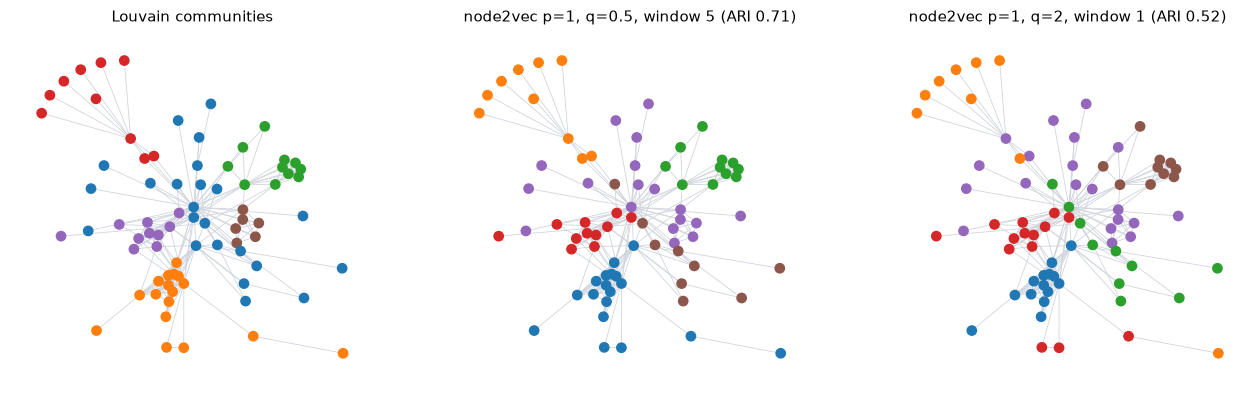

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from networkx.algorithms.community import louvain_communities
lm = T.lesmis()
louvain = sorted(louvain_communities(lm, seed=0), key=len, reverse=True)
community = np.zeros(len(lm), int)
for k, members in enumerate(louvain):
    community[list(members)] = k
print("characters:", lm.number_of_nodes(), "| co-appearance edges:", lm.number_of_edges(), "| Louvain communities:", len(louvain))
pos = nx.spring_layout(lm, seed=3)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
panels = [("Louvain communities", community)]
for p, q, window in [(1, .5, 5), (1, 2, 1)]:
    nodes, z, info = T.embed(lm, n_walks=10, length=40, window=window, dim=16, negatives=5, epochs=5, lr=.025, p=p, q=q)
    clusters = KMeans(6, n_init=10, random_state=0).fit_predict(z / np.linalg.norm(z, axis=1, keepdims=True))
    ari = adjusted_rand_score(community, clusters)
    print(f"p={p}, q={q}, window {window}: ARI with Louvain = {ari:.2f}")
    panels.append((f"node2vec p={p}, q={q}, window {window} (ARI {ari:.2f})", clusters))
for ax, (title, colours) in zip(axs, panels):
    nx.draw_networkx_edges(lm, pos, ax=ax, edge_color="#D0D5DD", width=.6)
    nx.draw_networkx_nodes(lm, pos, ax=ax, node_color=colours, cmap="tab10", vmin=0, vmax=9, node_size=45)
    ax.set_title(title, fontsize=11); ax.set_axis_off()
plt.show()

**Reading the output.** With $q = 0.5$ and window 5 the clusters agree well with the communities (ARI 0.71). With $q = 2$ and window 1, the setting closest to the paper's structural picture, the agreement is lower (0.52), but the clusters are still mostly communities: characters that bridge different parts of the novel do not group together, as roles would require. (Cluster colours are arbitrary in this plot; the slides match them to the Louvain panel.) The reason is that two nodes far apart rarely share a walk window, so walk-based vectors can hardly make them similar. struc2vec (Ribeiro, Saverese and Figueiredo, 2017) was designed for structural roles; one seed and one graph are, of course, limited evidence either way.

## W7 · DeepWalk on Cora: node classification under a fixed protocol
*Slides, Part 5.* Cora has 2,708 papers, 5,278 citations (treated as undirected), 1,433 binary word features and seven topics. The split is fixed: 541 papers for training, 541 for validation and 1,626 for test, stratified by topic (a local split with seed 5111, not the standard Planetoid split). The protocol is **transductive**: the embedding may use the whole citation graph, which contains no labels; test labels are hidden from training and from every choice of settings.

The configuration is fixed before any result is seen. `RUN_TRAINING = False` loads the reference embedding instead of training, if your runtime is slow.

In [15]:
G, X, y, paper_ids, classes, split = T.load_cora()
config = dict(n_walks=3, length=16, window=2, dim=16, negatives=3, epochs=2, lr=.03, p=1., q=1.)
RUN_TRAINING = True
if RUN_TRAINING:
    nodes, Z, training = T.embed(G, **config)
else:
    saved = np.load(T.ROOT / "reference/cora-s02-baseline.npz")
    Z = saved["embeddings"]; training = json.loads((T.ROOT / "reference/results.json").read_text())["training"]
    print("REFERENCE OUTPUTS: computed when the pack was prepared.")
print("embedding:", Z.shape, "| pairs:", training["pairs"], "| loss per positive pair by epoch:", np.round(training["loss_per_positive_pair"], 3))
reference = np.load(T.ROOT / "reference/cora-s02-baseline.npz")["embeddings"]
print("identical to the reference embedding:", np.allclose(Z, reference))

embedding: (2708, 16) | pairs: 471192 | loss per positive pair by epoch: [2.343 0.835]
identical to the reference embedding: True


We compare four representations with the same classifier, a logistic regression whose regularisation strength is chosen on the **validation** papers only: always predicting the largest topic, the Session 01 measures (degree, clustering, PageRank), the 1,433 word features, and the 16-dimensional walk embedding. **Predict before running:** rank the four by validation accuracy.

In [16]:
representations = {"Session 01 measures": T.structural_features(G), "word features": X, "walk embedding": Z}
models, validation = {}, []
for name, F in representations.items():
    result, models[name] = T.classify(F, y, split, test=False)
    validation.append({"representation": name, **result})
majority = np.bincount(y[split["train"]]).argmax()
validation.append({"representation": "majority class", "C": np.nan, "validation_accuracy": float(np.mean(y[split["val"]] == majority))})
display(pd.DataFrame(validation).set_index("representation").round(3))

,C,validation_accuracy
representation,,
Session 01 measures,10.0,0.325
word features,0.1,0.665
walk embedding,10.0,0.662
majority class,NaN,0.303


**Before the next cell:** the comparison is now frozen. The next cell evaluates each representation **once** on the 1,626 test papers. Any later change (W7's last cell, the practice notebook) uses validation accuracy only; returning to the test set to choose settings would turn it into a second validation set.

In [17]:
from sklearn.metrics import accuracy_score, f1_score
test_rows = []
for name, model in models.items():
    pred = model.predict(representations[name][split["test"]]); truth = y[split["test"]]
    test_rows.append({"representation": name, "test accuracy": accuracy_score(truth, pred), "test macro-F1": f1_score(truth, pred, average="macro")})
test_rows.append({"representation": "majority class", "test accuracy": float(np.mean(y[split["test"]] == majority)),
                  "test macro-F1": f1_score(y[split["test"]], np.full(len(split["test"]), majority), average="macro")})
display(pd.DataFrame(test_rows).set_index("representation").round(3))

,test accuracy,test macro-F1
representation,,
Session 01 measures,0.306,0.138
word features,0.649,0.618
walk embedding,0.631,0.614
majority class,0.302,0.066


**Reading the output.** The Session 01 measures reach 0.306, essentially the 0.302 of always predicting the largest topic. The walk embedding, learned from citations alone, reaches 0.631 (macro-F1 0.614), close to the 0.649 (macro-F1 0.618) obtained from all 1,433 word features. The reason is homophily: papers cite papers on the same topic, so where a paper sits in the graph says a great deal about its topic, while how many citations it has says almost nothing. Macro-F1 averages the F1 score of each topic with equal weight, so small topics count as much as large ones.

A projection to two dimensions is useful for exploring, but it is not evidence. PCA keeps the two directions of greatest variance; the colours are the true topics, added afterwards.

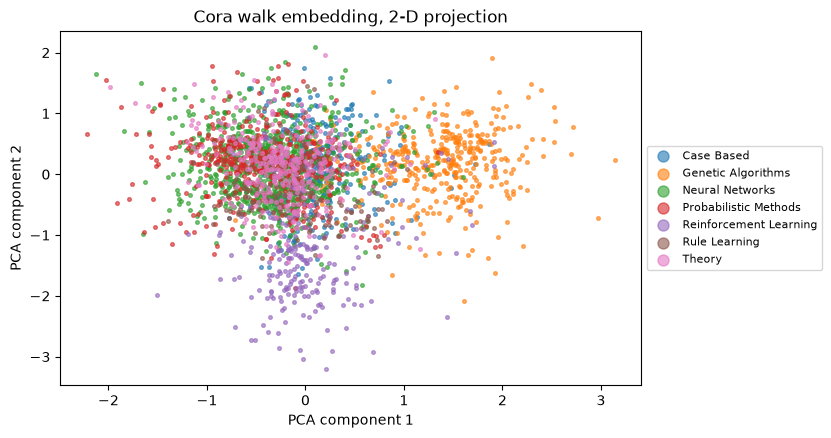

,paper id,true topic,predicted topic
0,101145,Case_Based,Rule_Learning
1,101263,Theory,Neural_Networks
2,1026,Genetic_Algorithms,Neural_Networks
3,103482,Neural_Networks,Genetic_Algorithms
4,108962,Probabilistic_Methods,Rule_Learning


In [18]:
from sklearn.decomposition import PCA
xy = PCA(n_components=2, random_state=SEED).fit_transform(Z)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for k, name in enumerate(classes):
    m = y == k
    ax.scatter(xy[m, 0], xy[m, 1], s=7, alpha=.6, label=name.replace("_", " "))
ax.set(xlabel="PCA component 1", ylabel="PCA component 2", title="Cora walk embedding, 2-D projection")
ax.legend(markerscale=3, fontsize=8, loc="center left", bbox_to_anchor=(1, .5)); plt.show()
truth = y[split["val"]]; pred = models["walk embedding"].predict(Z[split["val"]])
wrong = split["val"][pred != truth][:5]
display(pd.DataFrame({"paper id": paper_ids[wrong], "true topic": classes[y[wrong]],
                      "predicted topic": classes[models["walk embedding"].predict(Z[wrong])]}))

**Reading the output.** Genetic Algorithms and Reinforcement Learning form visible groups; the other topics overlap in two dimensions, although the classifier separates them partly in sixteen. The table lists five validation errors: before blaming the data, look at a paper's neighbours. A paper that cites mostly another topic is a reasonable error for a method that only sees citations.

Finally, node2vec's $q$ as a setting chosen on **validation** data, with everything else fixed. **Predict before running:** on a homophilous citation graph, will outward walks (small $q$) help or hurt?

In [19]:
rows = []
for q in [.5, 1., 2.]:
    nodes, Zq, _ = T.embed(G, **{**config, "q": q})
    rows.append({"q": q, "validation accuracy": T.classify(Zq, y, split)[0]["validation_accuracy"]})
display(pd.DataFrame(rows).set_index("q").round(3))

,validation accuracy
q,
0.5,0.671
1.0,0.662
2.0,0.627


**Reading the output.** Validation accuracy is 0.671 for $q = 0.5$, 0.662 for $q = 1$ and 0.627 for $q = 2$. Outward walks help slightly on this graph, where topic follows community. But this is one split and one seed: the difference between 0.671 and 0.662 is within the variation you would see by changing the seed, which the practice notebook (R2) measures.

**Group checkpoint B.** Record the validation table, one error from the list, and one explanation you could test by inspecting that paper's neighbours.

## W8 · Link prediction: hide edges first
*Slides, Part 5.* In link prediction the edges are the targets, so the split is over edges. `split_links` hides 10% of the citations for validation and 10% for test (527 each), pairs them with the same number of sampled non-edges, and returns the **training graph** without the hidden edges. A sampled non-edge is an assumed negative for this experiment, not proof that a citation could never exist.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
train_graph, positive, negative = T.split_links(G)
print("edges: full", G.number_of_edges(), "| training graph", train_graph.number_of_edges(),
      "| held out: validation", len(positive["val"]), "test", len(positive["test"]))
cn_val = T.common_neighbour_auc(train_graph, positive["val"], negative["val"])
cn_test = T.common_neighbour_auc(train_graph, positive["test"], negative["test"])
print(f"common-neighbour AUC: validation {cn_val:.3f} | test {cn_test:.3f}")

edges: full 5278 | training graph 4224 | held out: validation 527 test 527
common-neighbour AUC: validation 0.704 | test 0.720


The ROC AUC is the probability that a randomly chosen held-out edge scores higher than a randomly chosen non-edge: 0.5 is chance, 1 is perfect. The baseline scores a pair by its number of common neighbours, the triadic intuition of Session 01.

Now the walk embedding. We learn it on the **training graph only**, represent a pair $(u, v)$ by the Hadamard product $z_u \odot z_v$ (coordinate-by-coordinate multiplication), and train a logistic regression to separate training edges from training non-edges. **Predict before running:** will the embedding beat common neighbours?

In [21]:
def link_auc(graph):
    """Embed `graph`, train a link classifier on the training pairs, return validation and test AUC."""
    nodes, z, _ = T.embed(graph, n_walks=3, length=16, window=2, dim=16, negatives=3, epochs=2, lr=.03)
    Xtr = np.vstack([T.edge_features(z, positive["train"]), T.edge_features(z, negative["train"])])
    ytr = np.r_[np.ones(len(positive["train"])), np.zeros(len(negative["train"]))]
    clf = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
    out = {}
    for part in ["val", "test"]:
        Xs = np.vstack([T.edge_features(z, positive[part]), T.edge_features(z, negative[part])])
        ys = np.r_[np.ones(len(positive[part])), np.zeros(len(negative[part]))]
        out[part] = roc_auc_score(ys, clf.predict_proba(Xs)[:, 1])
    return out

honest = link_auc(train_graph)
print(f"embedding learned on the training graph: AUC validation {honest['val']:.3f} | test {honest['test']:.3f}")

embedding learned on the training graph: AUC validation 0.772 | test 0.790


**Reading the output.** The embedding reaches 0.772 on validation and 0.790 on test, against 0.704 and 0.720 for common neighbours.

**Predict before running:** in W7 we legitimately learned the embedding on the full graph. What happens if we reuse that habit here, learning the embedding on the full graph, which still contains the held-out edges?

In [22]:
leaky = link_auc(G)       # WRONG on purpose: the full graph contains the validation and test edges
print(f"embedding learned on the FULL graph: AUC validation {leaky['val']:.3f} | test {leaky['test']:.3f}")

embedding learned on the FULL graph: AUC validation 0.979 | test 0.986


**Reading the output.** The AUC jumps to 0.979 on validation and 0.986 on test. The walks crossed the held-out edges, so the vectors already encode the answer: this is **leakage**. The full-graph embedding was valid for node classification, where the targets were labels that the walks never see, and invalid here, where the targets are edges. What a model may see depends on the task, so the protocol has to be designed per task.

## W9 · Transductive and inductive: papers that arrive later
*Slides, Part 6.* DeepWalk learns one vector per node present in training. Suppose the 1,626 test papers are published **after** the model was trained. **Predict before running:** how many of them have a vector?

In [23]:
new = np.zeros(len(G), bool); new[split["test"]] = True
seen_graph = G.subgraph([n for n in G if not new[n]]).copy()
nodes_seen, Z_seen, _ = T.embed(seen_graph, n_walks=3, length=16, window=2, dim=16, negatives=3, epochs=2, lr=.03)
print("rows in the lookup table:", len(nodes_seen), "| new papers:", int(new.sum()),
      "| new papers with a row:", len(set(nodes_seen) & set(np.flatnonzero(new))))

rows in the lookup table: 1082 | new papers: 1626 | new papers with a row: 0


**Reading the output.** The table has 1,082 rows, one for each earlier paper, and none of the 1,626 new papers has one. A transductive method must be retrained on the enlarged graph. An **inductive** method instead learns a function that computes a vector from a node's own features and those of its neighbours, so it applies to any node.

Here is that idea with no training at all. Each paper is described by its own words plus the average of the words of the papers it cites **that already existed** (`visible = not new`); the training papers are described the same way, so one classifier serves old and new papers. **Predict before running:** will adding the neighbour average help the new papers?

In [24]:
X_mean, earlier_neighbours = T.neighbour_mean_features(G, X, visible=~new)
own, _ = T.classify(X, y, split, test=True)
both, _ = T.classify(X_mean, y, split, test=True)
display(pd.DataFrame([{"features": "own words only", **own}, {"features": "own words + mean of earlier neighbours' words", **both}]).set_index("features").round(3))
print("new papers that cite no earlier paper:", int((earlier_neighbours[new] == 0).sum()), "of", int(new.sum()))

,C,validation_accuracy,test_accuracy,test_macro_f1
features,,,,
own words only,0.1,0.665,0.649,0.618
own words + mean of earlier neighbours' words,0.1,0.710,0.733,0.714


new papers that cite no earlier paper: 382 of 1626


**Reading the output.** Accuracy on the new papers rises from 0.649 with their own words to 0.733 with the neighbour average added. 382 of the 1,626 new papers cite no earlier paper; their second half is zero and they fall back on their own words. This averaging is one GraphSAGE layer with the learned weights left out: GraphSAGE (Hamilton, Ying and Leskovec, 2017) samples a fixed number of neighbours and learns how to combine a node's own vector with the aggregate of its neighbours', with the same weights for every node, so it computes vectors for nodes never seen in training.

## W10 (optional) · TransE: a vector for a relation
*Slides, Part 6.* In a knowledge graph the facts are triples (head, relation, tail), such as (Valletta, capital_of, Malta). TransE (Bordes et al., 2013) gives every entity and every relation a vector and trains $h + r \approx t$ for true triples, against triples whose head or tail is replaced at random. `fit_transe` is a short teaching sketch; we train it on six capital-of triples in two dimensions.

r (capital_of): [-0.375 -0.373] | largest residual: 0.025


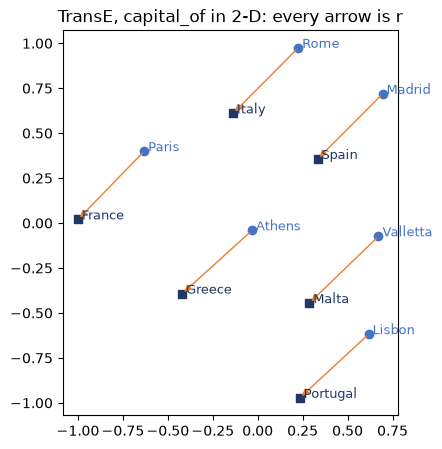

In [25]:
capitals = [("Malta", "Valletta"), ("Italy", "Rome"), ("France", "Paris"), ("Spain", "Madrid"), ("Greece", "Athens"), ("Portugal", "Lisbon")]
entities = [c for c, _ in capitals] + [city for _, city in capitals]
index = {e: i for i, e in enumerate(entities)}
triples = [(index[city], 0, index[country]) for country, city in capitals]     # relation 0 = capital_of
E, R = T.fit_transe(triples, len(entities), 1, dim=2, epochs=800, lr=.01, margin=.5)
residual = {f"{city} + r - {country}": float(np.linalg.norm(E[index[city]] + R[0] - E[index[country]])) for country, city in capitals}
print("r (capital_of):", R[0].round(3), "| largest residual:", round(max(residual.values()), 3))
fig, ax = plt.subplots(figsize=(5.5, 5))
for country, city in capitals:
    h, t = E[index[city]], E[index[country]]
    ax.annotate("", xy=t, xytext=h, arrowprops=dict(arrowstyle="-|>", color="#ED7D31"))
    ax.scatter(*h, color="#4472C4"); ax.scatter(*t, color="#1F3864", marker="s")
    ax.text(*h, " " + city, fontsize=9, color="#4472C4"); ax.text(*t, " " + country, fontsize=9, color="#1F3864")
ax.set_aspect("equal"); ax.set(title="TransE, capital_of in 2-D: every arrow is r"); plt.show()

**Reading the output.** All six arrows from a capital to its country are the same vector $r$, with a largest residual of 0.025. The simplicity has a cost: a one-to-many relation such as has_city would ask Italy + $r'$ to land on both Rome and Milan, which forces Rome and Milan together. The practice notebook (R6, optional) lets you see this happen.

## Exit check

Answer in one or two sentences each, in the cell below.

1. Name one choice made before any learning that changes the training pairs, and say how.
2. Why could the full graph be used for the embedding in W7 but not in W8?
3. What does a new paper need in order to receive a vector from a transductive method, and from an inductive one?

**My answers:** …

After the session, follow the Practice and Further Reading sheet: the practice notebook first, then the student notes where you need them.